In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import time

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "student_test"
OUTPUT_DIR = PROJECT_ROOT / "data" / "interim" / "candidates"

assert TRAIN_DIR.exists(), f"Missing {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Missing {TEST_DIR}"

print("Project:", PROJECT_ROOT)
print("Train:", TRAIN_DIR)
print("Student test:", TEST_DIR)
print("Output:", OUTPUT_DIR)


Project: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap
Train: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\data\processed\train
Student test: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\data\processed\student_test
Output: c:\Users\HP\.vscode\python\ml\mlcodes\ml_project\PathSnap\data\interim\candidates


In [3]:
# Shapely 2.x is required for STRtree.query(..., predicate='dwithin').
# If this import fails, install the dependencies in your active environment:
# %pip install "shapely>=2.0" pyproj scipy

import shapely
from shapely.geometry import LineString, Point
from shapely.strtree import STRtree
from pyproj import CRS, Transformer

print("Shapely:", shapely.__version__)
major = int(shapely.__version__.split(".")[0])
assert major >= 2, "Please install Shapely 2.x: %pip install --upgrade shapely"


Shapely: 2.2.0


In [4]:
def find_trip_dirs(partition_dir):
    required = {"track.csv", "nodes.csv", "arcs.csv", "route.csv"}
    return sorted(
        p for p in partition_dir.iterdir()
        if p.is_dir() and required.issubset({f.name for f in p.iterdir() if f.is_file()})
    )

def load_trip(folder):
    return {
        "track": pd.read_csv(folder / "track.csv"),
        "nodes": pd.read_csv(folder / "nodes.csv"),
        "arcs": pd.read_csv(folder / "arcs.csv"),
        "route": pd.read_csv(folder / "route.csv"),
    }

train_dirs = find_trip_dirs(TRAIN_DIR)
test_dirs = find_trip_dirs(TEST_DIR)
print("Train trips:", len(train_dirs), "| Student-test trips:", len(test_dirs))

pilot_dir = train_dirs[0]
pilot = load_trip(pilot_dir)
print("Pilot trip:", pilot_dir.name)
for name, df in pilot.items():
    print(name, df.shape, df.columns.tolist())
    display(df.head(3))


Train trips: 80 | Student-test trips: 10
Pilot trip: 00000001
track (1315, 4) ['observation_id', 'longitude', 'latitude', 'timestamp_s']


,observation_id,longitude,latitude,timestamp_s
0,0,8.595203,49.844053,1.0
1,1,8.595294,49.844441,2.0
2,2,8.595352,49.844883,3.0


nodes (88809, 3) ['node_id', 'longitude', 'latitude']


,node_id,longitude,latitude
0,0,8.581679,49.857880
1,1,8.584637,49.858295
2,2,8.580173,49.858567


arcs (165790, 3) ['arc_id', 'from_node_id', 'to_node_id']


,arc_id,from_node_id,to_node_id
0,0,0,281
1,1,0,1
2,2,0,5


route (525, 2) ['route_step', 'arc_id']


,route_step,arc_id
0,0,2641
1,1,64973
2,2,133948


In [5]:
# Explicit schema mapping. Change only if the schema printout above differs.
TRACK_LON, TRACK_LAT, TRACK_TIME = "longitude", "latitude", "timestamp_s"
NODE_LON, NODE_LAT = "longitude", "latitude"
ARC_FROM, ARC_TO = "from_node_id", "to_node_id"

required = {
    "track": {TRACK_LON, TRACK_LAT, TRACK_TIME},
    "nodes": {NODE_LON, NODE_LAT},
    "arcs": {ARC_FROM, ARC_TO},
}
for name, cols in required.items():
    missing = cols - set(pilot[name].columns)
    assert not missing, f"{name}.csv missing columns: {missing}"

assert len(pilot["track"]) > 0 and len(pilot["nodes"]) > 0 and len(pilot["arcs"]) > 0


In [6]:
def make_local_transformer(track):
    lon0 = float(track[TRACK_LON].median())
    lat0 = float(track[TRACK_LAT].median())
    local_crs = CRS.from_proj4(
        f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} +datum=WGS84 +units=m +no_defs"
    )
    transformer = Transformer.from_crs("EPSG:4326", local_crs, always_xy=True)
    return transformer, local_crs

def project_xy(frame, lon_col, lat_col, transformer):
    x, y = transformer.transform(
        frame[lon_col].to_numpy(dtype=float),
        frame[lat_col].to_numpy(dtype=float)
    )
    return np.asarray(x), np.asarray(y)

transformer, local_crs = make_local_transformer(pilot["track"])
gps_x, gps_y = project_xy(pilot["track"], TRACK_LON, TRACK_LAT, transformer)
node_x, node_y = project_xy(pilot["nodes"], NODE_LON, NODE_LAT, transformer)

print(local_crs)
print("GPS projected extent (m):", np.ptp(gps_x), "x", np.ptp(gps_y))
print("Node projected extent (m):", np.ptp(node_x), "x", np.ptp(node_y))


+proj=aeqd +lat_0=50.128292 +lon_0=8.603564 +datum=WGS84 +units=m +no_defs +type=crs
GPS projected extent (m): 5521.864940466651 x 40913.43976603321
Node projected extent (m): 6992.039692604176 x 43192.44827991389


In [7]:
def build_arc_geometries(nodes, arcs, node_x, node_y):
    src = pd.to_numeric(arcs[ARC_FROM], errors="coerce").to_numpy()
    dst = pd.to_numeric(arcs[ARC_TO], errors="coerce").to_numpy()

    if not np.isfinite(src).all() or not np.isfinite(dst).all():
        raise ValueError("Arc endpoint IDs contain non-numeric or non-finite values.")
    src = src.astype(np.int64)
    dst = dst.astype(np.int64)

    if (src < 0).any() or (dst < 0).any() or (src >= len(nodes)).any() or (dst >= len(nodes)).any():
        raise ValueError("Arc endpoint ID outside node row-position range.")

    geometries = []
    meta = []
    for arc_id, (u, v) in enumerate(zip(src, dst)):
        x1, y1 = node_x[u], node_y[u]
        x2, y2 = node_x[v], node_y[v]
        if not np.isfinite([x1, y1, x2, y2]).all():
            continue
        line = LineString([(x1, y1), (x2, y2)])
        if line.length <= 0:
            continue
        dx, dy = x2 - x1, y2 - y1
        bearing = (math.degrees(math.atan2(dx, dy)) + 360.0) % 360.0
        geometries.append(line)
        meta.append((arc_id, float(line.length), float(bearing), int(u), int(v)))

    meta_df = pd.DataFrame(meta, columns=["arc_id", "segment_length_m", "road_heading_deg", "from_node_id", "to_node_id"])
    return geometries, meta_df

pilot_geoms, pilot_arc_meta = build_arc_geometries(
    pilot["nodes"], pilot["arcs"], node_x, node_y
)
print("Usable geometries:", len(pilot_geoms), "of", len(pilot["arcs"]), "arcs")
display(pilot_arc_meta.head())


Usable geometries: 165782 of 165790 arcs


,arc_id,segment_length_m,road_heading_deg,from_node_id,to_node_id
0,0,78.426723,258.316123,0,281
1,1,217.651358,77.771522,0,1
2,2,103.474338,168.024045,0,5
3,3,217.651358,257.771522,1,0
4,4,45.364500,78.415869,1,40750


In [8]:
def circular_difference_deg(a, b):
    return np.abs((a - b + 180.0) % 360.0 - 180.0)

def gps_headings(x, y):
    n = len(x)
    headings = np.full(n, np.nan, dtype=float)
    for i in range(n):
        if i < n - 1:
            dx, dy = x[i + 1] - x[i], y[i + 1] - y[i]
        elif i > 0:
            dx, dy = x[i] - x[i - 1], y[i] - y[i - 1]
        else:
            continue
        if math.hypot(dx, dy) > 0.5:
            headings[i] = (math.degrees(math.atan2(dx, dy)) + 360.0) % 360.0
    return headings

gps_heading = gps_headings(gps_x, gps_y)
print("Observations with estimated heading:", int(np.isfinite(gps_heading).sum()), "/", len(gps_heading))


Observations with estimated heading: 1315 / 1315


In [9]:
RADII_M = [30.0, 60.0, 100.0]
MAX_CANDIDATES = 20

def generate_candidates(track, geometries, arc_meta, transformer,
                        radii_m=RADII_M, max_candidates=MAX_CANDIDATES):
    tree = STRtree(geometries)
    tx, ty = project_xy(track, TRACK_LON, TRACK_LAT, transformer)
    headings = gps_headings(tx, ty)
    meta = arc_meta.set_index("arc_id")

    rows = []
    for obs_pos, (x, y) in enumerate(zip(tx, ty)):
        point = Point(float(x), float(y))
        radius = max(radii_m)

        # Shapely 2 returns integer indices into the original geometry list.
        idx = np.asarray(tree.query(point, predicate="dwithin", distance=radius), dtype=int)
        used_fallback = len(idx) == 0
        if used_fallback:
            nearest_idx = int(tree.nearest(point))
            idx = np.array([nearest_idx], dtype=int)

        scored = []
        for geom_idx in idx:
            line = geometries[int(geom_idx)]
            distance = float(point.distance(line))
            arc_id = int(arc_meta.iloc[int(geom_idx)]["arc_id"])
            if not used_fallback and distance > radius:
                continue
            scored.append((distance, arc_id, line, int(geom_idx)))

        scored.sort(key=lambda item: item[0])
        scored = scored[:max_candidates]

        for rank, (distance, arc_id, line, geom_idx) in enumerate(scored, start=1):
            m = meta.loc[arc_id]
            projection = line.project(point)
            fraction = projection / line.length if line.length else 0.0
            projected_point = line.interpolate(projection)
            hdiff = (
                float(circular_difference_deg(headings[obs_pos], m["road_heading_deg"]))
                if np.isfinite(headings[obs_pos]) else np.nan
            )

            rows.append({
                "observation_pos": obs_pos,
                "observation_id": track.iloc[obs_pos].get("observation_id", obs_pos),
                "arc_id": arc_id,
                "candidate_rank": rank,
                "distance_m": distance,
                "distance_to_projected_point_m": float(point.distance(projected_point)),
                "segment_length_m": float(m["segment_length_m"]),
                "gps_heading_deg": headings[obs_pos],
                "road_heading_deg": float(m["road_heading_deg"]),
                "heading_difference_deg": hdiff,
                "projection_fraction": float(fraction),
                "used_fallback": bool(used_fallback),
                "search_radius_m": radius,
            })

    return pd.DataFrame(rows)

start = time.time()
pilot_candidates = generate_candidates(
    pilot["track"], pilot_geoms, pilot_arc_meta, transformer
)
print(f"Generated {len(pilot_candidates):,} candidate rows in {time.time()-start:.1f}s")
display(pilot_candidates.head(10))


Generated 21,842 candidate rows in 1.8s


,observation_pos,observation_id,arc_id,candidate_rank,distance_m,distance_to_projected_point_m,segment_length_m,gps_heading_deg,road_heading_deg,heading_difference_deg,projection_fraction,used_fallback,search_radius_m
0,0,0.0,64973,1,0.723049,0.723049,293.352246,8.630643,7.317066,1.313576,0.109775,False,100.0
1,0,0.0,117639,2,15.138380,15.138380,1020.835864,8.630643,187.386430,178.755787,0.512692,False,100.0
2,0,0.0,2641,3,32.210996,32.210996,425.215971,8.630643,7.188148,1.442495,1.000000,False,100.0
3,0,0.0,53932,4,93.046268,93.046268,169.107907,8.630643,356.786956,11.843687,0.154792,False,100.0
4,0,0.0,50652,5,93.046268,93.046268,169.107907,8.630643,176.786956,168.156313,0.845208,False,100.0
5,0,0.0,53933,6,96.658251,96.658251,274.679372,8.630643,173.570022,164.939379,0.000000,False,100.0
6,0,0.0,50653,7,96.658251,96.658251,274.679372,8.630643,353.570022,15.060621,1.000000,False,100.0
7,0,0.0,50585,8,96.658251,96.658251,225.221128,8.630643,279.641836,88.988807,1.000000,False,100.0
8,0,0.0,53934,9,96.658251,96.658251,225.221128,8.630643,99.641836,91.011193,0.000000,False,100.0
9,1,1.0,64973,1,0.277576,0.277576,293.352246,4.856659,7.317066,2.460407,0.258531,False,100.0


Observations: 1315
Observations with >=1 candidate: 1315
Mean candidates per observation: 16.609885931558935
Median candidates per observation: 20.0
Maximum candidates: 20
Fallback observations: 0
Fallback rate: 0.0


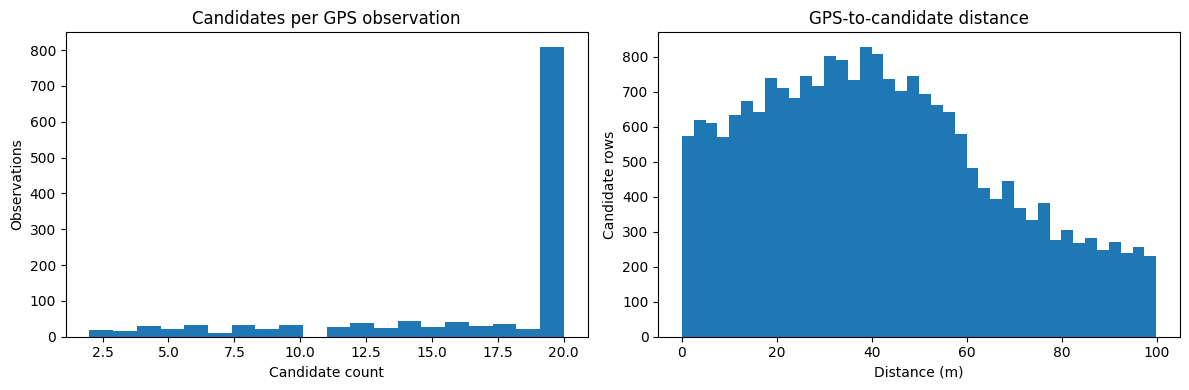

In [10]:
candidate_counts = pilot_candidates.groupby("observation_pos").size()
fallback_by_obs = pilot_candidates.groupby("observation_pos")["used_fallback"].first()

print("Observations:", len(pilot["track"]))
print("Observations with >=1 candidate:", candidate_counts.index.nunique())
print("Mean candidates per observation:", candidate_counts.mean())
print("Median candidates per observation:", candidate_counts.median())
print("Maximum candidates:", candidate_counts.max())
print("Fallback observations:", int(fallback_by_obs.sum()))
print("Fallback rate:", float(fallback_by_obs.mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(candidate_counts, bins=20)
axes[0].set_title("Candidates per GPS observation")
axes[0].set_xlabel("Candidate count")
axes[0].set_ylabel("Observations")
axes[1].hist(pilot_candidates["distance_m"], bins=40)
axes[1].set_title("GPS-to-candidate distance")
axes[1].set_xlabel("Distance (m)")
axes[1].set_ylabel("Candidate rows")
plt.tight_layout()
plt.show()


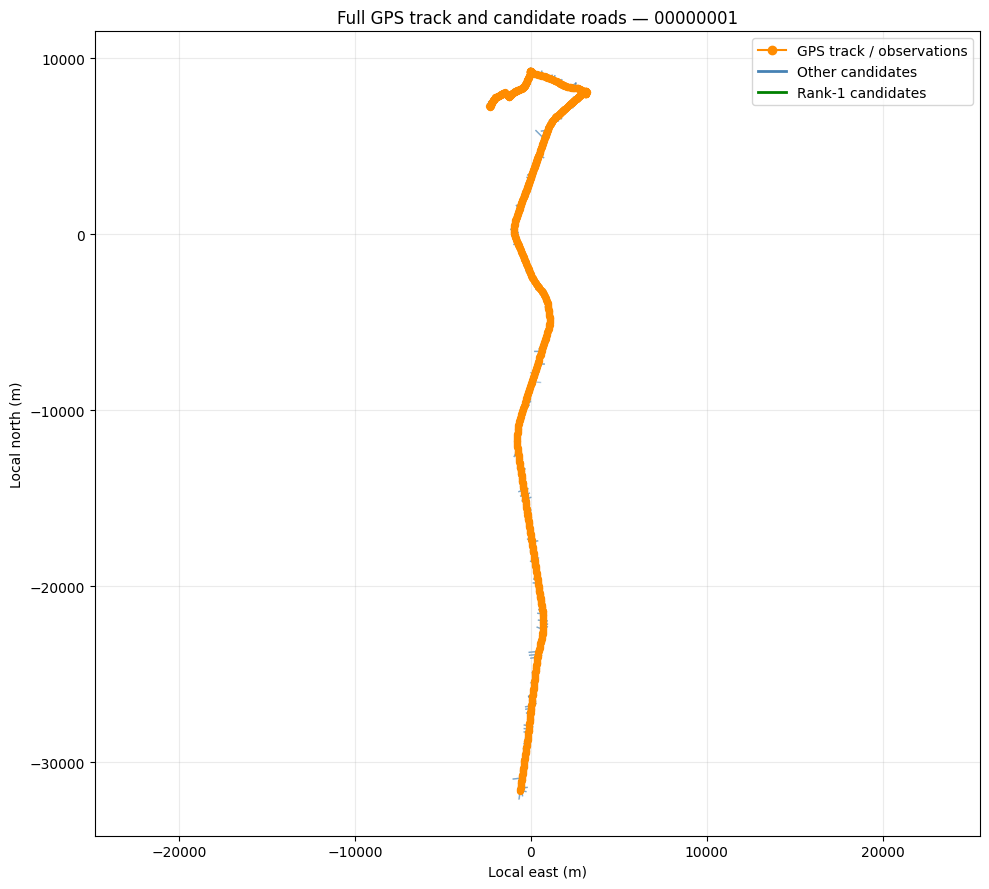

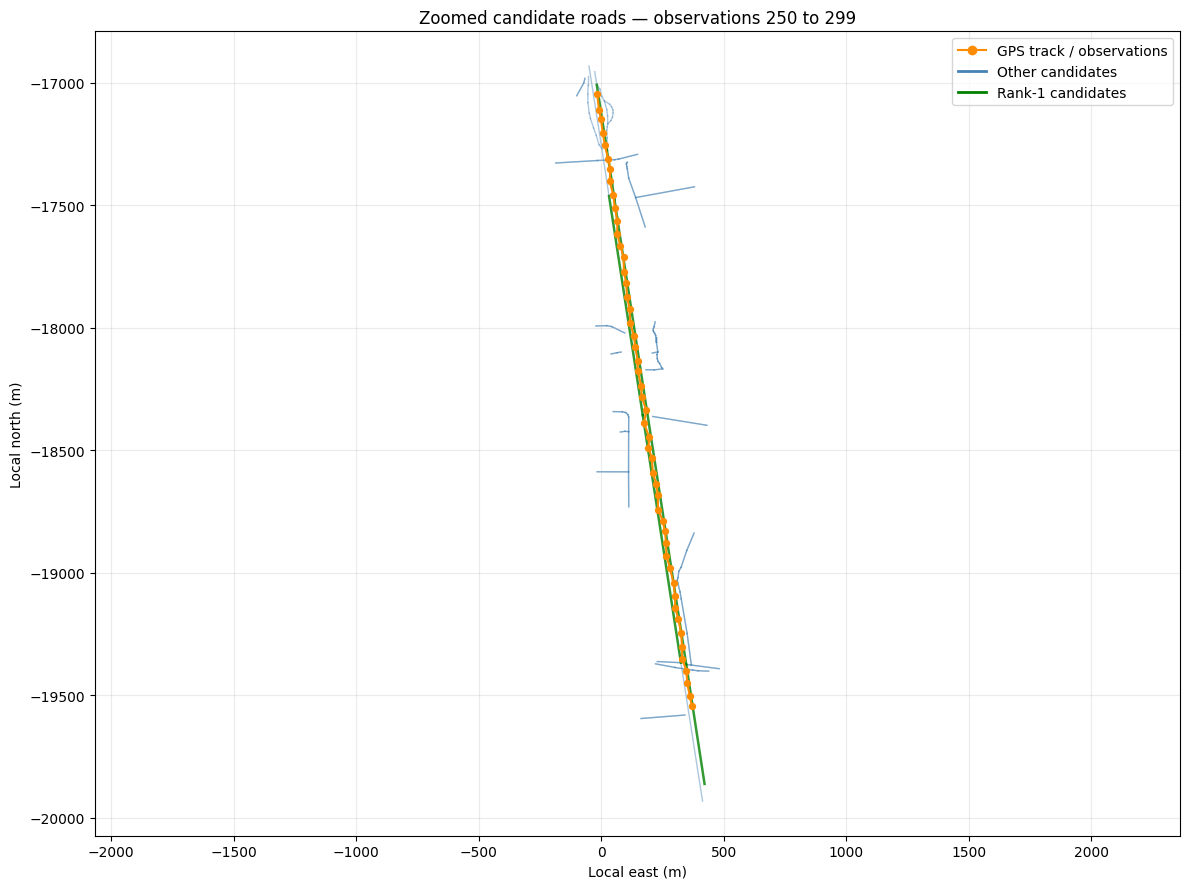

In [11]:
ZOOM_START = 250
ZOOM_COUNT = 50

end_pos = min(ZOOM_START + ZOOM_COUNT, len(pilot["track"]))
zoom_positions = np.arange(ZOOM_START, end_pos)

geom_by_arc = {int(row.arc_id): pilot_geoms[i] for i, row in pilot_arc_meta.iterrows()}

def plot_candidate_map(positions, title, figsize=(11, 8)):
    selected = pilot_candidates[pilot_candidates["observation_pos"].isin(positions)]
    candidate_ids = selected["arc_id"].astype(int).unique()
    best_ids = set(selected.loc[selected["candidate_rank"] == 1, "arc_id"].astype(int))

    fig, ax = plt.subplots(figsize=figsize)

    for arc_id in candidate_ids:
        line = geom_by_arc.get(int(arc_id))
        if line is None:
            continue
        xx, yy = line.xy
        if int(arc_id) in best_ids:
            ax.plot(xx, yy, color="green", linewidth=1.8, alpha=0.8, zorder=2)
        else:
            ax.plot(xx, yy, color="steelblue", linewidth=1.0, alpha=0.45, zorder=1)

    gps_slice = pilot["track"].iloc[positions]
    ax.plot(gps_x[positions], gps_y[positions], color="darkorange", linewidth=1.5,
            marker="o", markersize=3, label="GPS track", zorder=4)
    ax.scatter(gps_x[positions], gps_y[positions], color="darkorange", s=18,
               label="GPS observations", zorder=5)

    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0], [0], color="darkorange", marker="o", label="GPS track / observations"),
        Line2D([0], [0], color="steelblue", linewidth=2, label="Other candidates"),
        Line2D([0], [0], color="green", linewidth=2, label="Rank-1 candidates"),
    ]
    ax.legend(handles=legend_items)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(title)
    ax.set_xlabel("Local east (m)")
    ax.set_ylabel("Local north (m)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_candidate_map(np.arange(len(pilot["track"])),
                   f"Full GPS track and candidate roads — {pilot_dir.name}", figsize=(10, 9))

plot_candidate_map(zoom_positions,
                   f"Zoomed candidate roads — observations {ZOOM_START} to {end_pos - 1}", figsize=(12, 9))


In [13]:
RUN_ALL_TRAIN = True

def process_trip(folder):
    data = load_trip(folder)
    transformer, _ = make_local_transformer(data["track"])
    gx, gy = project_xy(data["nodes"], NODE_LON, NODE_LAT, transformer)
    geoms, meta = build_arc_geometries(data["nodes"], data["arcs"], gx, gy)
    candidates = generate_candidates(data["track"], geoms, meta, transformer)
    candidates.insert(0, "trip_id", folder.name)
    return candidates

if RUN_ALL_TRAIN:
    out_dir = OUTPUT_DIR / "train"
    out_dir.mkdir(parents=True, exist_ok=True)
    summaries = []
    for i, folder in enumerate(train_dirs, start=1):
        t0 = time.time()
        candidates = process_trip(folder)
        out_path = out_dir / f"trip_{folder.name}_candidates.csv"
        candidates.to_csv(out_path, index=False)
        obs_count = candidates["observation_pos"].nunique()
        summaries.append({
            "trip_id": folder.name,
            "candidate_rows": len(candidates),
            "observations": obs_count,
            "fallback_observations": int(candidates.groupby("observation_pos")["used_fallback"].first().sum()),
            "runtime_seconds": time.time() - t0,
            "output_file": str(out_path),
        })
        print(f"[{i}/{len(train_dirs)}] {folder.name}: {len(candidates):,} rows, {time.time()-t0:.1f}s")

    batch_summary = pd.DataFrame(summaries)
    display(batch_summary)
    batch_summary.to_csv(OUTPUT_DIR / "train_candidate_summary.csv", index=False)
else:
    print("Pilot only. Set RUN_ALL_TRAIN = True after reviewing pilot diagnostics.")


[1/80] 00000001: 21,842 rows, 3.8s
[2/80] 00000002: 109,555 rows, 9.4s
[3/80] 00000003: 15,858 rows, 2.0s
[4/80] 00000004: 12,280 rows, 1.0s
[5/80] 00000005: 4,781 rows, 0.4s
[6/80] 00000006: 21,411 rows, 1.8s
[7/80] 00000008: 61,105 rows, 4.8s
[8/80] 00000010: 51,927 rows, 5.0s
[9/80] 00000011: 26,882 rows, 2.2s
[10/80] 00000012: 10,211 rows, 1.1s
[11/80] 00000013: 36,101 rows, 5.8s
[12/80] 00000014: 8,547 rows, 0.9s
[13/80] 00000016: 24,712 rows, 2.4s
[14/80] 00000018: 7,101 rows, 0.8s
[15/80] 00000019: 33,449 rows, 3.9s
[16/80] 00000020: 13,634 rows, 1.1s
[17/80] 00000021: 71,800 rows, 5.4s
[18/80] 00000022: 8,624 rows, 1.0s
[19/80] 00000024: 10,560 rows, 1.3s
[20/80] 00000025: 19,955 rows, 2.4s
[21/80] 00000026: 6,088 rows, 0.5s
[22/80] 00000027: 9,364 rows, 0.7s
[23/80] 00000028: 42,392 rows, 4.5s
[24/80] 00000029: 13,972 rows, 1.5s
[25/80] 00000031: 58,935 rows, 6.0s
[26/80] 00000032: 29,327 rows, 4.9s
[27/80] 00000033: 106,961 rows, 8.3s
[28/80] 00000034: 47,404 rows, 5.3s
[29/8

,trip_id,candidate_rows,observations,fallback_observations,runtime_seconds,output_file
0,00000001,21842,1315,0,3.790619,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
1,00000002,109555,7243,271,9.412079,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
2,00000003,15858,821,0,1.981524,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
3,00000004,12280,1064,0,1.042008,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
4,00000005,4781,1045,0,0.391730,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
...,...,...,...,...,...,...
75,00000095,28754,1551,0,3.353896,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
76,00000096,34565,3271,10,3.844357,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
77,00000097,24334,1740,0,3.391531,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
78,00000098,57070,5584,0,6.567880,c:\Users\HP\.vscode\python\ml\mlcodes\ml_proje...
